# Solution: Plotting Weather data on maps

In this notebook we analyse temperature records. We analyse a [snapshot](https://huggingface.co/datasets/haesleinhuepf/dwd_temperature_july2026) of the data that was saved right after the summer heatwave in Germany 2026.
The data originated from Deutscher Wetterdienst (DWD) Open Data portal. Source: https://opendata.dwd.de/, licensed CC-BY 4.0 Read more: https://www.dwd.de/EN/service/legal_notice/legal_notice_node.html

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import stackview
import os

If the data is not present yet, we download it.

In [2]:
if not os.path.exists("temp_recent.parquet"):
    from datasets import load_dataset
    
    ds = load_dataset("haesleinhuepf/dwd_temperature_july2026")
    
    # Save one split as Parquet
    ds["train"].to_parquet("temp_recent.parquet")

We connect to Blablador.

In [3]:
from bia_bob import config_blablador, bob

config_blablador()

The data looks like the following. The most important columns are:
* `TT_10` average temperature measured in a time-window of 10 minutes.
* `Stationsname` physical place (city) of the measurement
* `geoBreite` and `geoLaenge` latitude and longitude coordinate of the measurement station
* `MESS_DATUM` date and time of the measurement in format `YYYYMMDDhhmm`.

In [4]:
df = pd.read_parquet("temp_recent.parquet")
df.head()

,STATIONS_ID,MESS_DATUM,QN,PP_10,TT_10,TM5_10,RF_10,TD_10,eor,Stations_id,von_datum,bis_datum,Stationshoehe,geoBreite,geoLaenge,Stationsname,Bundesland,Abgabe,datetime
0,44,202412310000,3,-999.0,6.4,6.0,87.3,4.4,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:00:00
1,44,202412310010,3,-999.0,6.4,6.1,86.9,4.4,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:10:00
2,44,202412310020,3,-999.0,6.4,5.9,87.5,4.5,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:20:00
3,44,202412310030,3,-999.0,6.4,6.0,87.1,4.4,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:30:00
4,44,202412310040,3,-999.0,6.4,5.9,87.9,4.5,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:40:00


In [5]:
%%bob
There is a file named "germany_federal_states.geojson" (utf-8 encoded) which contains coordinates 
of federal state borders in Germany. You can use it for plotting. 
    
The file structure roughly looks like this:
```
{
"type": "FeatureCollection",
"name": "germany_federal_states",
"crs": { "type": "name", "properties": { "name": "urn:ogc:def:crs:OGC:1.3:CRS84" } },
"features": [
{ "type": "Feature", "properties": { "featurecla": "Admin-1 states provinces", "scalerank": 3, "adm1_code": "DEU-1601", "diss_me": 1601, "iso_3166_2": "DE-SN", "wikipedia": null, "iso_a2": "DE", "adm0_sr": 1, "name": "Sachsen", "name_alt": "Saxony", "name_local": null, "type": "Land", "type_en": "State", "code_local": null, "code_hasc": "DE.SN", "note": null, "hasc_maybe": null, "region": null, "region_cod": null, "provnum_ne": 13.0, "gadm_level": 1, "check_me": 20, "datarank": 3, "abbrev": null, "postal": "SN", "area_sqkm": 0.0, "sameascity": -99, "labelrank": 3, "name_len": 7, "mapcolor9": 5, "mapcolor13": 1, "fips": "GM13", "fips_alt": null, "woe_id": 2345493.0, "woe_label": "Saxony, DE, Germany", "woe_name": "Sachsen", "latitude": 51.0053, "longitude": 13.4596, "sov_a3": "DEU", "adm0_a3": "DEU", "adm0_label": 2, "admin": "Germany", "geonunit": "Germany", "gu_a3": "DEU", "gn_id": 2842566.0, "gn_name": "Freistaat Sachsen", "gns_id": -1854402.0, "gns_name": "Sachsen", "gn_level": 1.0, "gn_region": null, "gn_a1_code": "DE.13", "region_sub": null, "sub_code": null, "gns_level": 1.0, "gns_lang": "zho", "gns_adm1": "GM13", "gns_region": null, "min_label": 6.6, "max_label": 11.0, "min_zoom": 6.6, "wikidataid": "Q1202", "name_ar": "سكسونيا", "name_bn": "জাখসেন", "name_de": "Sachsen", "name_en": "Saxony", "name_es": "Sajonia", "name_fr": "Saxe", "name_el": "Σαξονία", "name_hi": "सैक्सोनी", "name_hu": "Szászország", "name_id": "Sachsen", "name_it": "Sassonia", "name_ja": "ザクセン州", "name_ko": "작센", "name_nl": "Saksen", "name_pl": "Saksonia", "name_pt": "Saxónia", "name_ru": "Саксония", "name_sv": "Sachsen", "name_tr": "Saksonya", "name_vi": "Sachsen", "name_zh": "萨克森", "ne_id": 1159312773, "name_he": "סקסוניה", "name_uk": "Саксонія", "name_ur": "زاکسن", "name_fa": "زاکسن", "name_zht": "薩克森", "FCLASS_ISO": null, "FCLASS_US": null, "FCLASS_FR": null, "FCLASS_RU": null, "FCLASS_ES": null, "FCLASS_CN": null, "FCLASS_TW": null, "FCLASS_IN": null, "FCLASS_NP": null, "FCLASS_PK": null, "FCLASS_DE": null, "FCLASS_GB": null, "FCLASS_BR": null, "FCLASS_IL": null, "FCLASS_PS": null, "FCLASS_SA": null, "FCLASS_EG": null, "FCLASS_MA": null, "FCLASS_PT": null, "FCLASS_AR": null, "FCLASS_JP": null, "FCLASS_KO": null, "FCLASS_VN": null, "FCLASS_TR": null, "FCLASS_ID": null, "FCLASS_PL": null, "FCLASS_GR": null, "FCLASS_IT": null, "FCLASS_NL": null, "FCLASS_SE": null, "FCLASS_BD": null, "FCLASS_UA": null, "FCLASS_TLC": null }, "geometry": { "type": "Polygon", "coordinates": [ [ [ 14.39780806400006, 51.013114726000097 ], [ 14.386749308000049, 51.013269756000042 ], [ 14.375897257000076, 51.016990459000041 ], [ 14.369386027000104, 51.022442322000117 ], [ 14.364115031000097, 51.027997538000037 ], [ 14.356570272000056, 51.032338359 ], [ 14.319363240000115, 51.04001230900009 ], [ 14.287530558000071, 51.03683420800003 ], [ 14.263552694000055, 51.021434632000037 ], [ 14.249496704000137, 50.992650859000022 ], [     
```

Also, in df are two columns "geoBreite" and "geoLaenge" corresponding to latitute 
and longitude coordinates of the measurements.

Write a function which plots the measurement column "TT_10" in colours over the corresponding coordinates
on top of the map of Germany (in black-white).
Then, plot the measurements where "MESS_DATUM" is "202606291200".

I will load the GeoJSON file containing German federal state borders, define a function that draws the map in black-and-white and overlays the `TT_10` measurements as a colored scatter plot at the corresponding `geoLaenge`/`geoBreite` coordinates, then call it for the subset where `MESS_DATUM` equals `202606291200`.



In [6]:
import json

with open("germany_federal_states.geojson", encoding="utf-8") as f:
    geojson = json.load(f)


def plot_tt10_on_germany(data, geojson=geojson, column="TT_10"):
    fig, ax = plt.subplots(figsize=(8, 10))

    # Draw state borders (black-white map)
    for feature in geojson["features"]:
        geom = feature["geometry"]
        polygons = [geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]
        for poly in polygons:
            for ring in poly:
                ring = np.asarray(ring)
                ax.plot(ring[:, 0], ring[:, 1], color="black", linewidth=0.5)

    # Overlay colored measurements
    sc = ax.scatter(data["geoLaenge"], data["geoBreite"],
                    c=data[column], cmap="viridis", s=20, edgecolors="k", linewidths=0.2)
    plt.colorbar(sc, ax=ax, label=column, shrink=0.7)

    ax.set_aspect("equal")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(f"{column} over Germany")
    plt.tight_layout()
    plt.show()


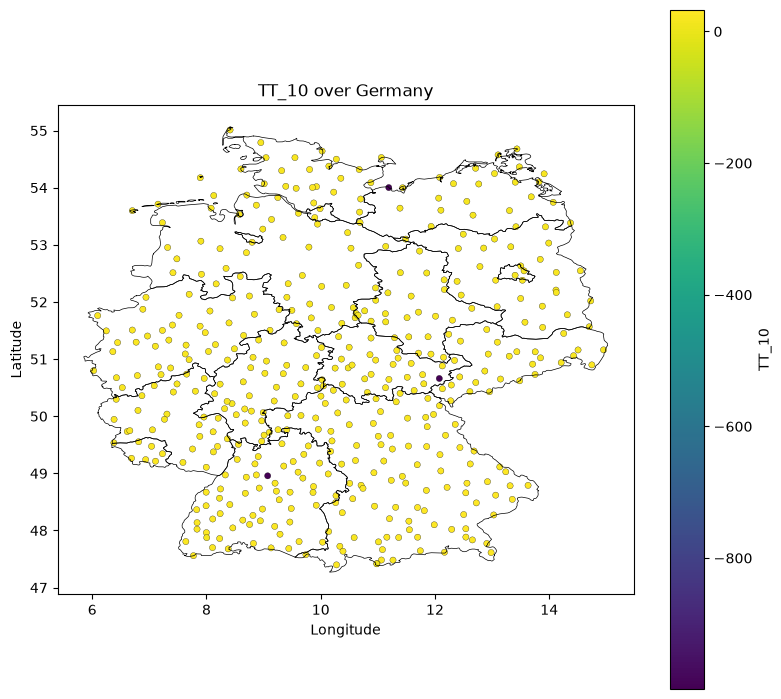

In [7]:
# Filter for the requested timestamp and plot
subset = df[df["MESS_DATUM"].astype(str) == "202606291200"]
plot_tt10_on_germany(subset)

## Exercise
Modify the plot above to show blue-red colours ranging from -40 to +40 degrees.

In [ ]:
%%bob
Plot the same data again, but this time with temperatures from -40 to +40 plotted in blue-red .

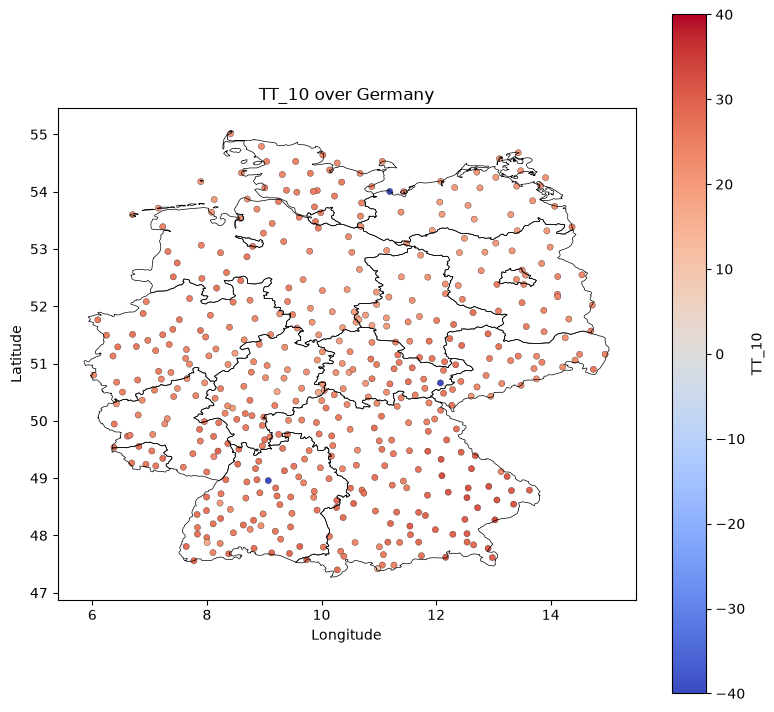

In [9]:
import json

with open("germany_federal_states.geojson", encoding="utf-8") as f:
    geojson = json.load(f)


def plot_tt10_on_germany(data, geojson=geojson, column="TT_10"):
    fig, ax = plt.subplots(figsize=(8, 10))

    # Draw state borders (black-white map)
    for feature in geojson["features"]:
        geom = feature["geometry"]
        polygons = [geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]
        for poly in polygons:
            for ring in poly:
                ring = np.asarray(ring)
                ax.plot(ring[:, 0], ring[:, 1], color="black", linewidth=0.5)

    # Overlay colored measurements (blue-red, fixed range -40..+40)
    sc = ax.scatter(data["geoLaenge"], data["geoBreite"],
                    c=data[column], cmap="coolwarm", vmin=-40, vmax=40,
                    s=20, edgecolors="k", linewidths=0.2)
    plt.colorbar(sc, ax=ax, label=column, shrink=0.7)

    ax.set_aspect("equal")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(f"{column} over Germany")
    plt.tight_layout()
    plt.show()


# Filter for the requested timestamp and plot
subset = df[df["MESS_DATUM"].astype(str) == "202606291200"]
plot_tt10_on_germany(subset)

## Advanced exercise

Plot a timelapse of the temperatures over a single day. 

Hint: As this is quite challenging, you may need to optimize the prompt multiple times and try repeatedly.

In [10]:
%%bob
Now generate a timelapse as animated gif of 24 timepoints between 202606291200 and 202606301200

I will build an animated GIF of 24 hourly timepoints from `202606291200` up to (but excluding) `202606301200`, reusing the black-white Germany map and the blue-red `TT_10` color scale (-40…+40). Only timepoints actually present in `df` are kept, and the animation is saved as a GIF.



In [11]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

with open("germany_federal_states.geojson", encoding="utf-8") as f:
    geojson = json.load(f)

In [12]:
# 24 hourly timepoints between the two timestamps (start inclusive, end exclusive)
hours = pd.date_range("2026-06-29 12:00", "2026-06-30 12:00", freq="h", inclusive="left")
mess_values = hours.strftime("%Y%m%d%H%M").astype(np.int64)

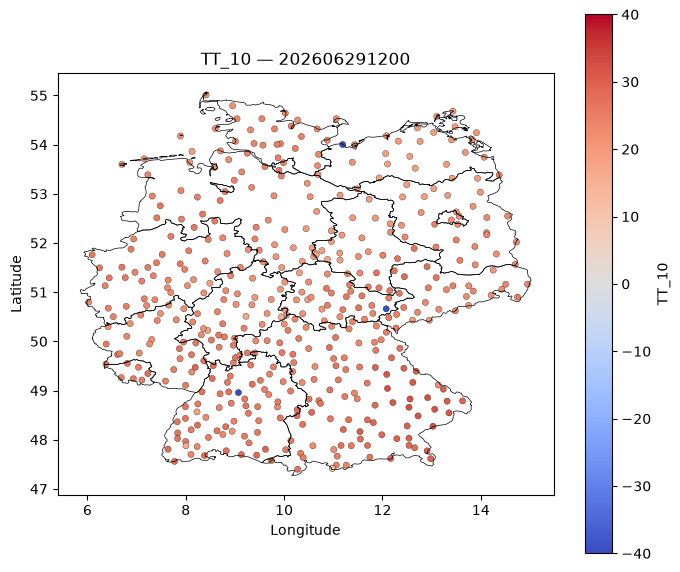

In [19]:
# keep only timepoints that actually exist in df
existing = set(df["MESS_DATUM"].astype(np.int64).unique())
mess_values = [t for t in mess_values if t in existing]


def draw_borders(ax):
    for feature in geojson["features"]:
        geom = feature["geometry"]
        polygons = [geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]
        for poly in polygons:
            for ring in poly:
                ring = np.asarray(ring)
                ax.plot(ring[:, 0], ring[:, 1], color="black", linewidth=0.5)


fig, ax = plt.subplots(figsize=(8, 10))
draw_borders(ax)
ax.set_aspect("equal")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

scat = ax.scatter(df["geoLaenge"], df["geoBreite"],
                    c=df["TT_10"], cmap="coolwarm", vmin=-40, vmax=40,
                    s=20, edgecolors="k", linewidths=0.2)
plt.colorbar(scat, ax=ax, label="TT_10", shrink=0.7)
title = ax.set_title("")


def update(i):
    t = mess_values[i]
    d = df[df["MESS_DATUM"].astype(np.int64) == t]
    scat.set_offsets(np.c_[d["geoLaenge"], d["geoBreite"]])
    scat.set_array(d["TT_10"].to_numpy())
    title.set_text(f"TT_10 — {t}")
    return scat, title


anim = FuncAnimation(fig, update, frames=len(mess_values), interval=400, blit=False)
anim.save("tt10_timelapse.gif", writer=PillowWriter(fps=3))

In [15]:
%%bob
Load "tt10_timelapse.gif" as numpy array and visualize it using stackview.

I will load every frame of `tt10_timelapse.gif` into a NumPy array using Pillow and display the animation with `stackview.animate`.



C:\Users\haase\miniforge3\envs\bob-env\Lib\site-packages\stackview\_animate.py:63: UserWarning: The image is quite large (> 10 MByte) and might not be properly shown in the notebook when rendered over the internet. Consider subsampling or cropping the image for visualization purposes.
  warnings.warn("The image is quite large (> 10 MByte) and might not be properly shown in the notebook when rendered over the internet. Consider subsampling or cropping the image for visualization purposes.")



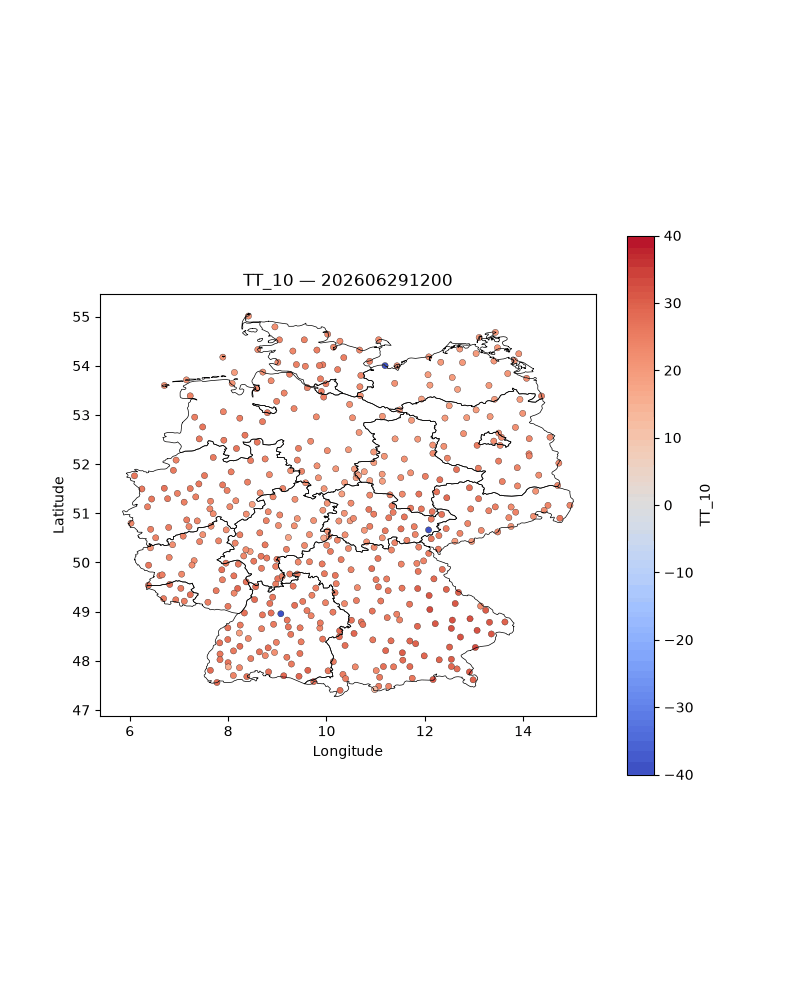

In [20]:
import numpy as np
import stackview
from PIL import Image, ImageSequence

with Image.open("tt10_timelapse.gif") as im:
    frames = [np.array(frame.convert("RGB")) for frame in ImageSequence.Iterator(im)]

anim = np.stack(frames)  # (frames, height, width, 3)

stackview.animate(anim)